## EDA VISUALISATIONS

## 1. correlation between Gender Pay Gap Indicators

Generating additional EDA visualisations...
Dataset shape: (74777, 41)


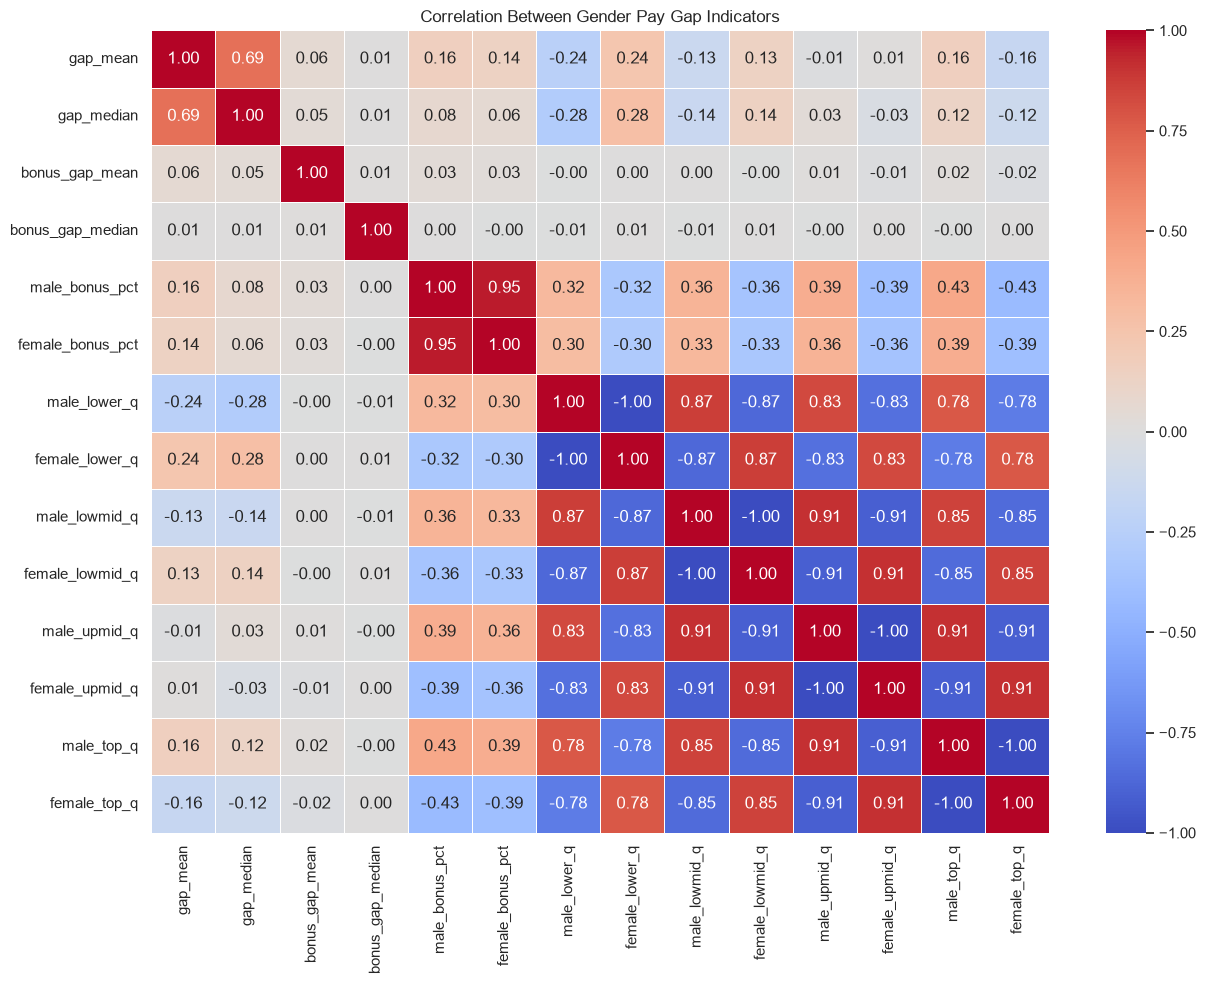

In [15]:

# ============================================================
# ADDITIONAL EDA VISUALISATIONS
# Uses the existing employer-year panel: data
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (12, 6)

# Verify dataset
assert "data" in globals(), "The employer-year panel 'data' has not been loaded."

print("Generating additional EDA visualisations...")
print(f"Dataset shape: {data.shape}")

# ------------------------------------------------------------
# 1. CORRELATION HEATMAP
# ------------------------------------------------------------

correlation_columns = [
    "gap_mean",
    "gap_median",
    "bonus_gap_mean",
    "bonus_gap_median",
    "male_bonus_pct",
    "female_bonus_pct",
    "male_lower_q",
    "female_lower_q",
    "male_lowmid_q",
    "female_lowmid_q",
    "male_upmid_q",
    "female_upmid_q",
    "male_top_q",
    "female_top_q"
]

available_corr = [
    col for col in correlation_columns
    if col in data.columns
]

if len(available_corr) >= 2:
    plt.figure(figsize=(13, 10))

    correlation_matrix = data[available_corr].corr(
        numeric_only=True
    )

    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        center=0,
        fmt=".2f",
        linewidths=0.5
    )

    plt.title("Correlation Between Gender Pay Gap Indicators")
    plt.tight_layout()
    plt.show()
else:
    print("Correlation heatmap skipped.")




## 2.  Median GENDER PAY GAP DISTRIBUTION

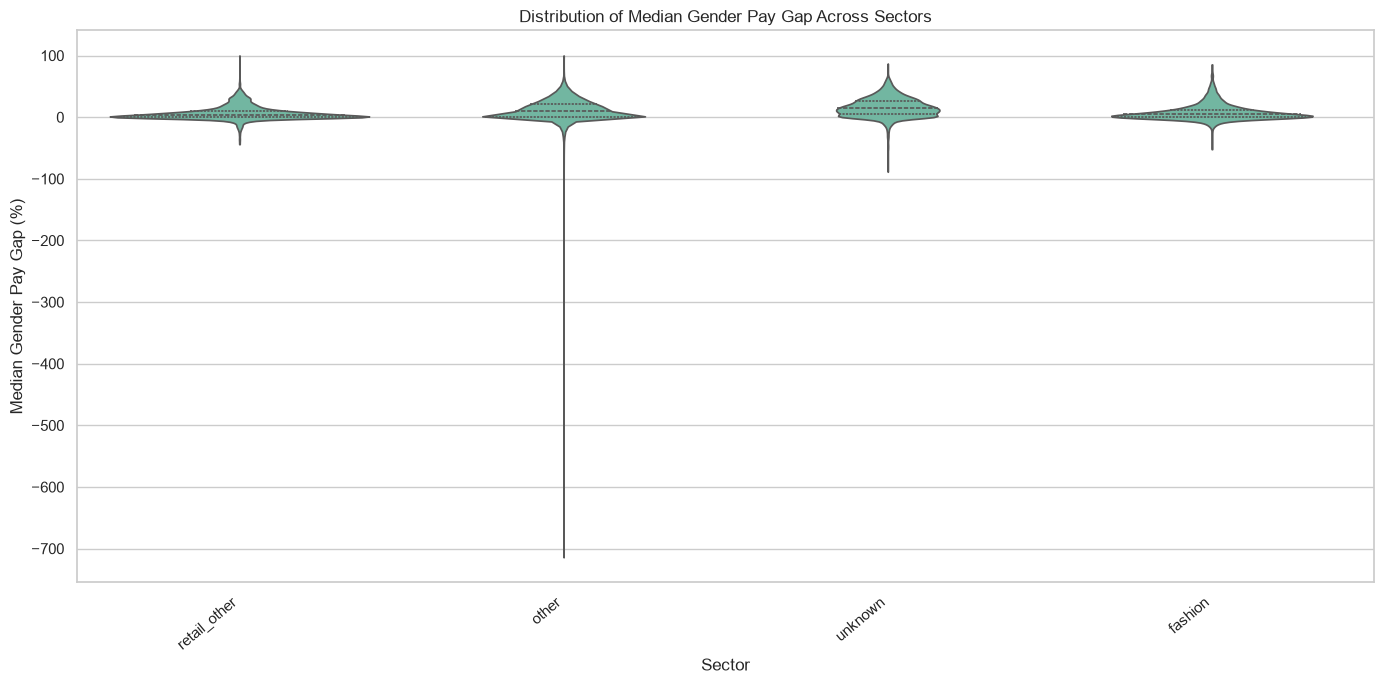

In [11]:
# ------------------------------------------------------------
# 2. SECTOR-WISE GENDER PAY GAP DISTRIBUTION
# ------------------------------------------------------------

if {"sector", "gap_median"}.issubset(data.columns):

    sector_data = data[
        ["sector", "gap_median"]
    ].dropna()

    top_sectors = (
        sector_data["sector"]
        .value_counts()
        .head(10)
        .index
    )

    sector_data = sector_data[
        sector_data["sector"].isin(top_sectors)
    ]

    plt.figure(figsize=(14, 7))

    sns.violinplot(
        data=sector_data,
        x="sector",
        y="gap_median",
        inner="quartile",
        cut=0
    )

    plt.title("Distribution of Median Gender Pay Gap Across Sectors")
    plt.xlabel("Sector")
    plt.ylabel("Median Gender Pay Gap (%)")
    plt.xticks(rotation=40, ha="right")
    plt.tight_layout()
    plt.show()


## 3. Average Median Gender Pay Gap Trends

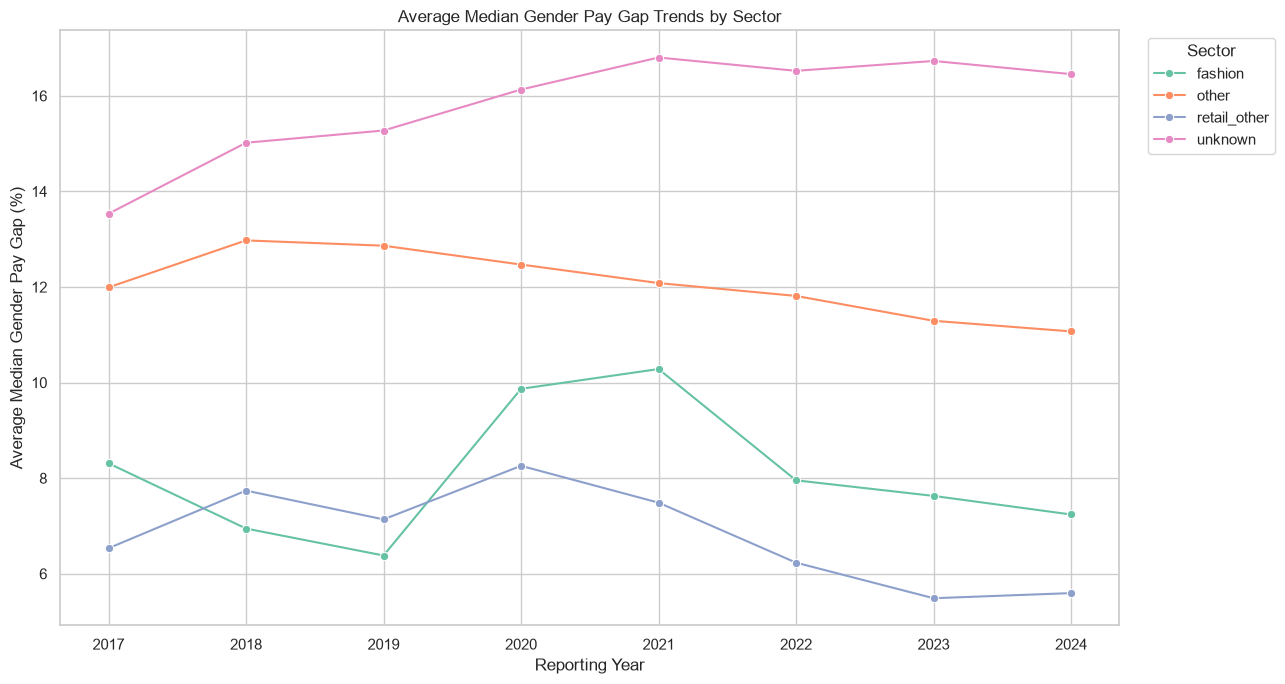

In [12]:
# ------------------------------------------------------------
# 3. GENDER PAY GAP TRENDS BY SECTOR
# ------------------------------------------------------------

if {"report_year", "sector", "gap_median"}.issubset(data.columns):

    trend_data = (
        data.groupby(
            ["report_year", "sector"],
            observed=True
        )["gap_median"]
        .mean()
        .reset_index()
    )

    top_sectors = (
        data["sector"]
        .value_counts()
        .head(6)
        .index
    )

    trend_data = trend_data[
        trend_data["sector"].isin(top_sectors)
    ]

    plt.figure(figsize=(13, 7))

    sns.lineplot(
        data=trend_data,
        x="report_year",
        y="gap_median",
        hue="sector",
        marker="o"
    )

    plt.title("Average Median Gender Pay Gap Trends by Sector")
    plt.xlabel("Reporting Year")
    plt.ylabel("Average Median Gender Pay Gap (%)")
    plt.xticks(sorted(trend_data["report_year"].dropna().unique()))
    plt.legend(title="Sector", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

## 4. Average Gender Representation Across Pay Quartiles

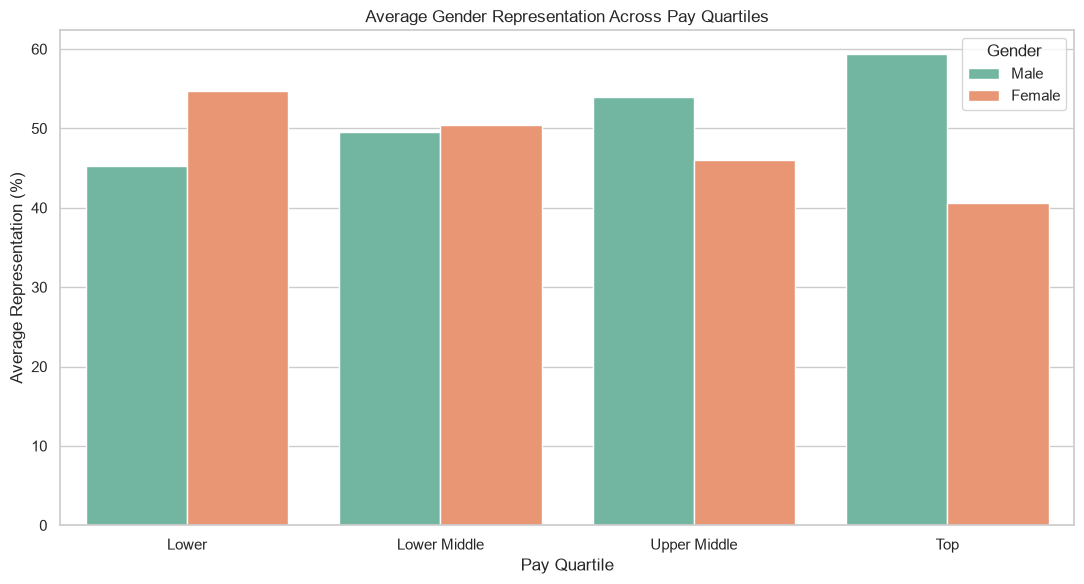

In [16]:
# ------------------------------------------------------------
# 4. GENDER REPRESENTATION ACROSS PAY QUARTILES
# ------------------------------------------------------------

quartile_columns = {
    "Lower": ("male_lower_q", "female_lower_q"),
    "Lower Middle": ("male_lowmid_q", "female_lowmid_q"),
    "Upper Middle": ("male_upmid_q", "female_upmid_q"),
    "Top": ("male_top_q", "female_top_q")
}

if all(
    col in data.columns
    for pair in quartile_columns.values()
    for col in pair
):

    quartile_summary = pd.DataFrame({
        "Quartile": list(quartile_columns.keys()),
        "Male": [
            data[male].mean()
            for male, female in quartile_columns.values()
        ],
        "Female": [
            data[female].mean()
            for male, female in quartile_columns.values()
        ]
    })

    quartile_plot = quartile_summary.melt(
        id_vars="Quartile",
        var_name="Gender",
        value_name="Average Representation (%)"
    )

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=quartile_plot,
        x="Quartile",
        y="Average Representation (%)",
        hue="Gender"
    )

    plt.title("Average Gender Representation Across Pay Quartiles")
    plt.xlabel("Pay Quartile")
    plt.ylabel("Average Representation (%)")
    plt.tight_layout()
    plt.show()

##  5. MEAN VERSUS MEDIAN GENDER PAY GAP

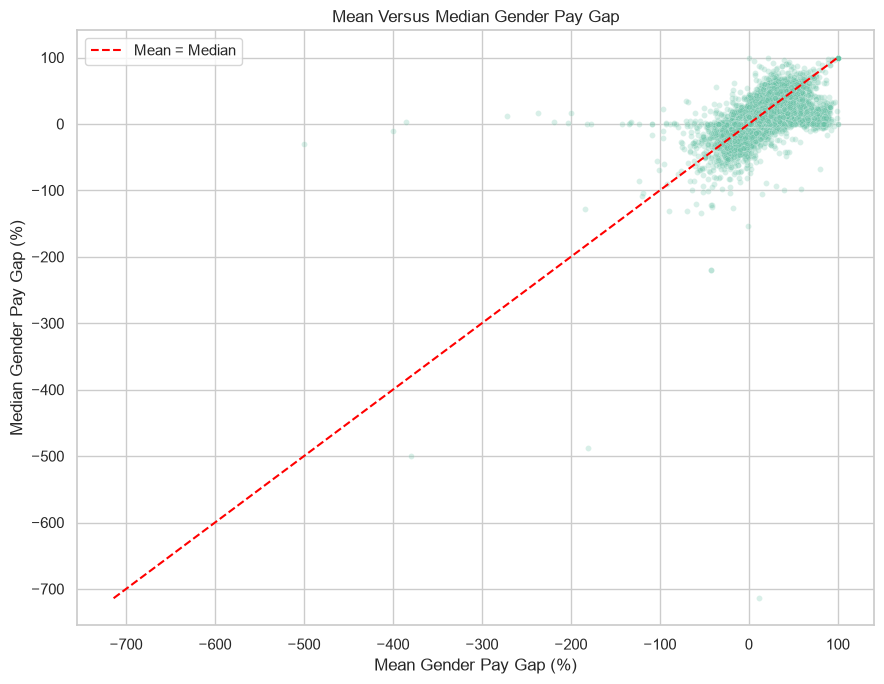


ADDITIONAL EDA VISUALISATIONS COMPLETED


In [14]:
# ------------------------------------------------------------
# 5. MEAN VERSUS MEDIAN GENDER PAY GAP
# ------------------------------------------------------------

if {"gap_mean", "gap_median"}.issubset(data.columns):

    scatter_data = data[
        ["gap_mean", "gap_median"]
    ].dropna()

    plt.figure(figsize=(9, 7))

    sns.scatterplot(
        data=scatter_data,
        x="gap_mean",
        y="gap_median",
        alpha=0.25,
        s=18
    )

    # Reference line: equality between mean and median gaps
    lower = min(
        scatter_data["gap_mean"].min(),
        scatter_data["gap_median"].min()
    )

    upper = max(
        scatter_data["gap_mean"].max(),
        scatter_data["gap_median"].max()
    )

    plt.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--",
        color="red",
        label="Mean = Median"
    )

    plt.title("Mean Versus Median Gender Pay Gap")
    plt.xlabel("Mean Gender Pay Gap (%)")
    plt.ylabel("Median Gender Pay Gap (%)")
    plt.legend()
    plt.tight_layout()
    plt.show()


print("\n" + "=" * 55)
print("ADDITIONAL EDA VISUALISATIONS COMPLETED")
print("=" * 55)


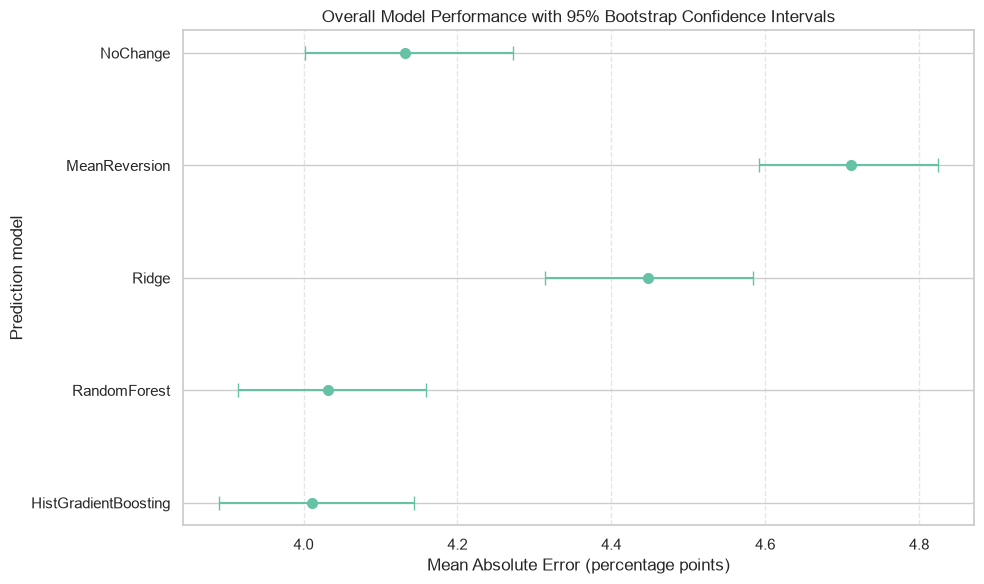

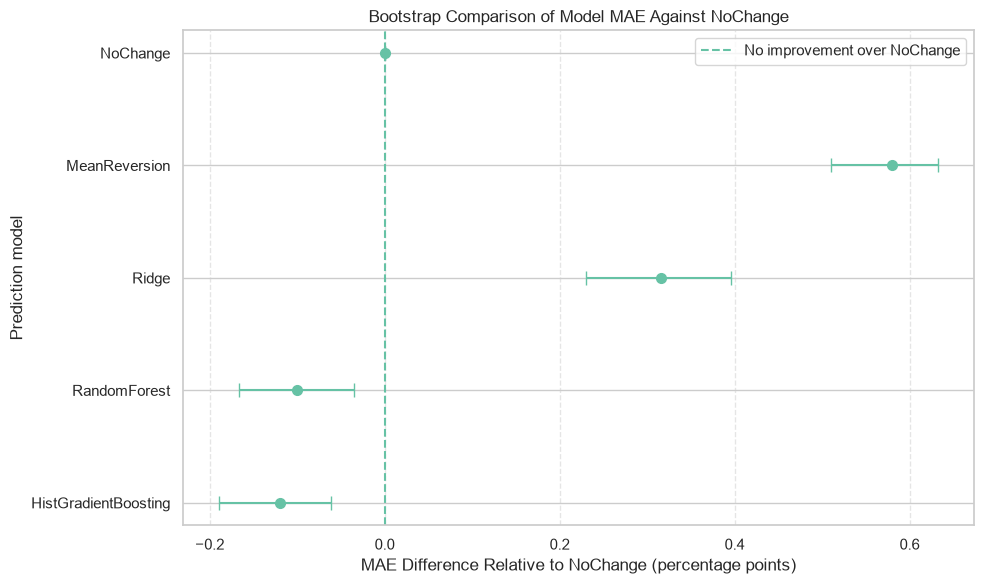

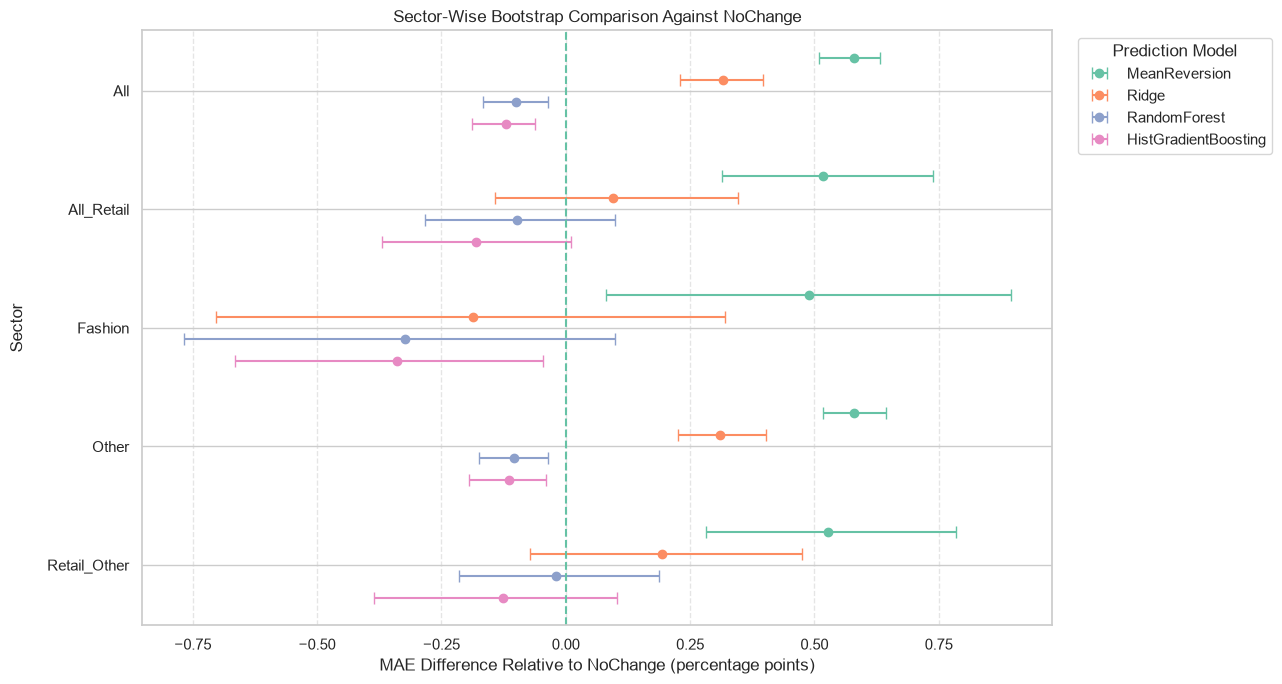


BOOTSTRAP VISUALISATIONS COMPLETED
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\research_figures\figure_bootstrap_mae_difference.png
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\research_figures\figure_bootstrap_overall_mae.png
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\research_figures\figure_bootstrap_sector_comparison.png

All figures saved at 300 DPI.


In [18]:
# ============================================================
# BOOTSTRAP VISUALISATIONS FOR IEEE RESEARCH PAPER
# Uses existing bootstrap CSV files - NO pipeline rerun
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. LOAD EXISTING RESULTS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project"
)

OUTPUT_DIR = PROJECT_DIR / "outputs" / "main" / "tables"
FIGURE_DIR = PROJECT_DIR / "outputs" / "research_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

bootstrap = pd.read_csv(
    OUTPUT_DIR / "bootstrap_results_2024.csv"
)

sector_bootstrap = pd.read_csv(
    OUTPUT_DIR / "sector_bootstrap_2024.csv"
)

# Clean column names, including the leading spaces in '    group'
bootstrap.columns = bootstrap.columns.str.strip()
sector_bootstrap.columns = sector_bootstrap.columns.str.strip()

model_order = [
    "NoChange",
    "MeanReversion",
    "Ridge",
    "RandomForest",
    "HistGradientBoosting"
]

# Consistent ordering
bootstrap["model"] = pd.Categorical(
    bootstrap["model"],
    categories=model_order,
    ordered=True
)

sector_bootstrap["model"] = pd.Categorical(
    sector_bootstrap["model"],
    categories=model_order,
    ordered=True
)

# ============================================================
# FIGURE 1: OVERALL MAE WITH 95% BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================

plot_data = bootstrap.sort_values("model").copy()

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(plot_data))

lower_error = plot_data["MAE"] - plot_data["MAE_lo"]
upper_error = plot_data["MAE_hi"] - plot_data["MAE"]

ax.errorbar(
    plot_data["MAE"],
    x,
    xerr=[lower_error, upper_error],
    fmt="o",
    capsize=5,
    markersize=7
)

ax.set_yticks(x)
ax.set_yticklabels(plot_data["model"].astype(str))
ax.invert_yaxis()

ax.set_xlabel("Mean Absolute Error (percentage points)")
ax.set_ylabel("Prediction model")
ax.set_title(
    "Overall Model Performance with 95% Bootstrap Confidence Intervals"
)

ax.grid(axis="x", linestyle="--", alpha=0.5)
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "figure_bootstrap_overall_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2: MAE DIFFERENCE AGAINST NOCHANGE
# ============================================================

plot_data = bootstrap.sort_values("model").copy()

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(plot_data))

lower_error = (
    plot_data["MAE_diff_vs_NoChange"] - plot_data["diff_lo"]
)

upper_error = (
    plot_data["diff_hi"] - plot_data["MAE_diff_vs_NoChange"]
)

ax.errorbar(
    plot_data["MAE_diff_vs_NoChange"],
    x,
    xerr=[lower_error, upper_error],
    fmt="o",
    capsize=5,
    markersize=7
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.5,
    label="No improvement over NoChange"
)

ax.set_yticks(x)
ax.set_yticklabels(plot_data["model"].astype(str))
ax.invert_yaxis()

ax.set_xlabel(
    "MAE Difference Relative to NoChange (percentage points)"
)
ax.set_ylabel("Prediction model")

ax.set_title(
    "Bootstrap Comparison of Model MAE Against NoChange"
)

ax.legend()
ax.grid(axis="x", linestyle="--", alpha=0.5)
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "figure_bootstrap_mae_difference.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 3: SECTOR-WISE MAE DIFFERENCE AGAINST NOCHANGE
# ============================================================

sector_data = sector_bootstrap[
    sector_bootstrap["group"].astype(str).str.lower() != "all"
].copy()

sector_data["group"] = sector_data["group"].astype(str)

sector_data = sector_data[
    sector_data["model"].astype(str) != "NoChange"
].copy()

groups = sorted(sector_data["group"].unique())

models = [
    model for model in model_order
    if model != "NoChange"
]

fig, ax = plt.subplots(figsize=(13, 7))

group_positions = np.arange(len(groups))
offsets = np.linspace(-0.28, 0.28, len(models))

for i, model in enumerate(models):

    model_data = (
        sector_data[
            sector_data["model"].astype(str) == model
        ]
        .set_index("group")
        .reindex(groups)
    )

    positions = group_positions + offsets[i]

    values = model_data["MAE_diff_vs_NoChange"].to_numpy(
        dtype=float
    )

    lower = model_data["diff_lo"].to_numpy(dtype=float)
    upper = model_data["diff_hi"].to_numpy(dtype=float)

    valid = (
        np.isfinite(values)
        & np.isfinite(lower)
        & np.isfinite(upper)
    )

    ax.errorbar(
        values[valid],
        positions[valid],
        xerr=[
            values[valid] - lower[valid],
            upper[valid] - values[valid]
        ],
        fmt="o",
        capsize=4,
        markersize=6,
        label=model
    )

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.5
)

ax.set_yticks(group_positions)
ax.set_yticklabels([g.title() for g in groups])
ax.invert_yaxis()

ax.set_xlabel(
    "MAE Difference Relative to NoChange (percentage points)"
)
ax.set_ylabel("Sector")

ax.set_title(
    "Sector-Wise Bootstrap Comparison Against NoChange"
)

ax.legend(
    title="Prediction Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(axis="x", linestyle="--", alpha=0.5)
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "figure_bootstrap_sector_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# COMPLETION AND FILE LOCATIONS
# ============================================================

print("\n" + "=" * 65)
print("BOOTSTRAP VISUALISATIONS COMPLETED")
print("=" * 65)

for file in sorted(FIGURE_DIR.glob("figure_bootstrap_*.png")):
    print(file)

print("\nAll figures saved at 300 DPI.")

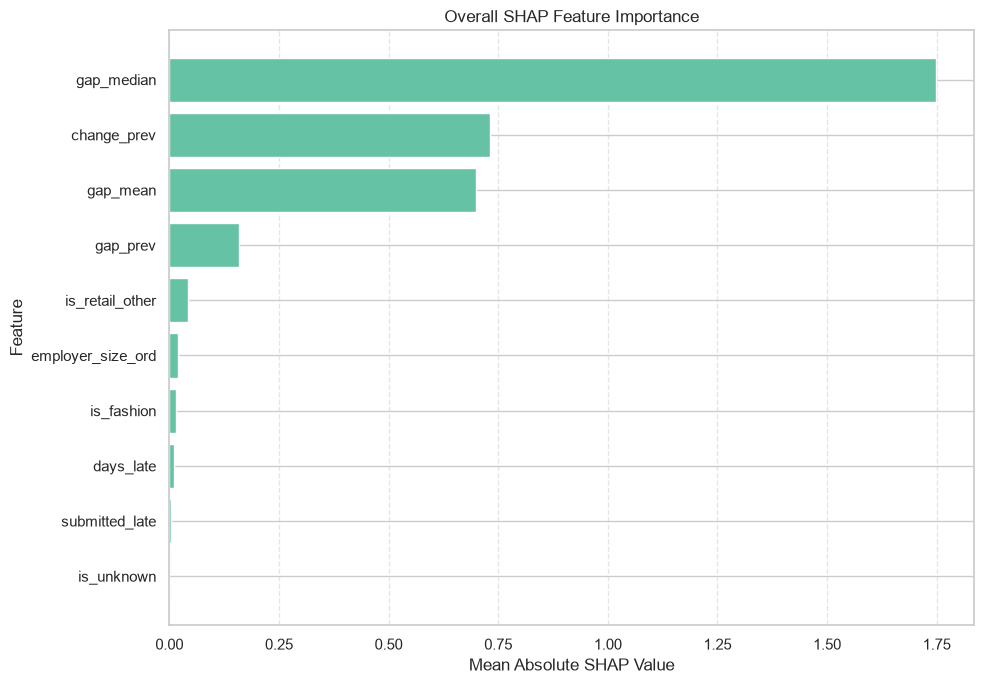

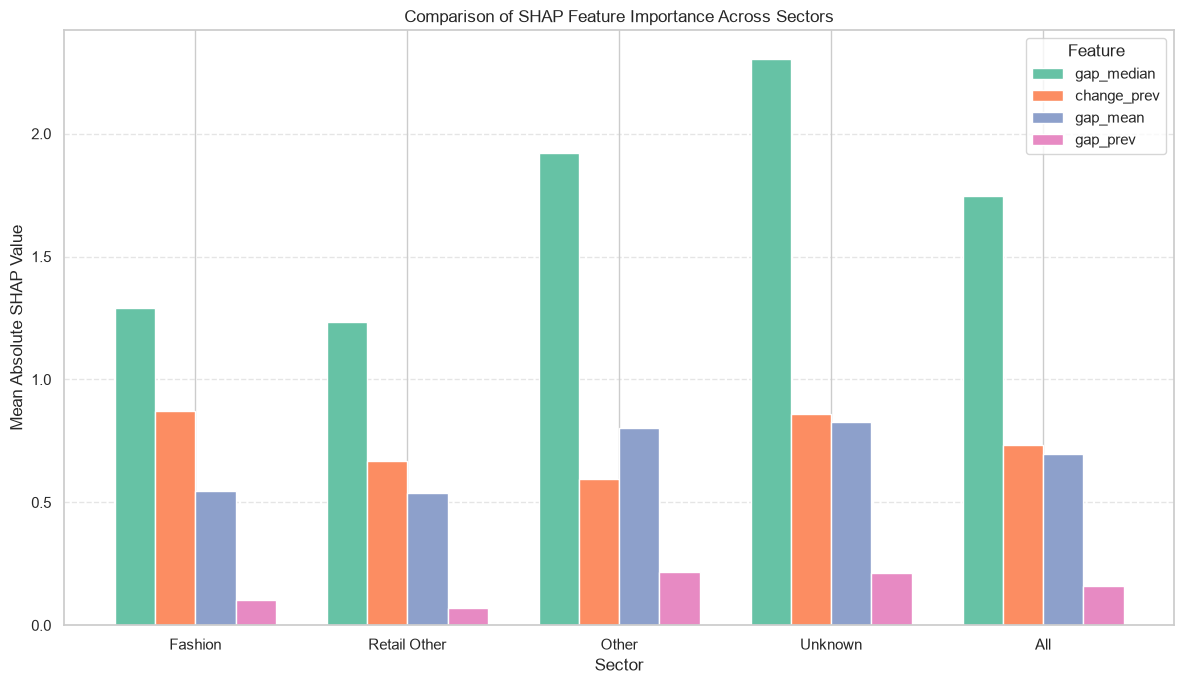

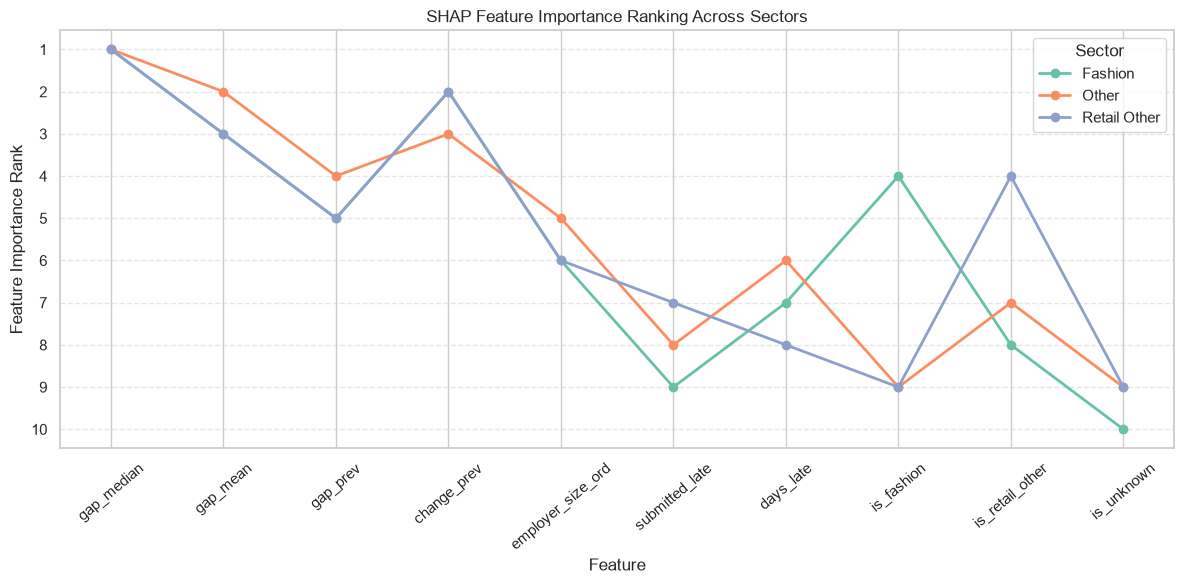


SHAP RANK AGREEMENT RESULTS
spearman_fashion_vs_other: 0.772040040473682
p_value: 0.008879536829615705

SHAP VISUALISATIONS COMPLETED
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\research_figures\figure_shap_feature_ranking.png
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\research_figures\figure_shap_overall_importance.png
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\research_figures\figure_shap_sector_comparison.png

All figures saved at 300 DPI.


In [19]:

# ============================================================
# SHAP VISUALISATIONS FOR IEEE RESEARCH PAPER
# Reuses existing SHAP outputs - no recalculation
# ============================================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_DIR = Path(
    r"C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project"
)

TABLE_DIR = PROJECT_DIR / "outputs" / "main" / "tables"
FIGURE_DIR = PROJECT_DIR / "outputs" / "research_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Load existing SHAP outputs
shap_data = pd.read_csv(
    TABLE_DIR / "shap_mean_abs_by_sector.csv"
)

rank_data = pd.read_csv(
    TABLE_DIR / "shap_rank_agreement.csv"
)

shap_data.columns = shap_data.columns.str.strip()
rank_data.columns = rank_data.columns.str.strip()

# ------------------------------------------------------------
# FIGURE 1: OVERALL SHAP FEATURE IMPORTANCE
# ------------------------------------------------------------

overall = shap_data[
    shap_data["sector"].astype(str).str.lower() == "all"
].iloc[0]

feature_columns = [
    col for col in shap_data.columns
    if col != "sector"
]

importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": [overall[col] for col in feature_columns]
})

importance = importance.sort_values(
    "Importance",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    importance["Feature"],
    importance["Importance"]
)

ax.set_xlabel("Mean Absolute SHAP Value")
ax.set_ylabel("Feature")
ax.set_title("Overall SHAP Feature Importance")

ax.grid(axis="x", linestyle="--", alpha=0.5)
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "figure_shap_overall_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FIGURE 2: SHAP IMPORTANCE BY SECTOR
# ------------------------------------------------------------

selected_features = [
    "gap_median",
    "change_prev",
    "gap_mean",
    "gap_prev"
]

sector_order = [
    "fashion",
    "retail_other",
    "other",
    "unknown",
    "all"
]

sector_plot = shap_data[
    shap_data["sector"].isin(sector_order)
].copy()

sector_plot["sector"] = pd.Categorical(
    sector_plot["sector"],
    categories=sector_order,
    ordered=True
)

sector_plot = sector_plot.sort_values("sector")

fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(sector_plot))
width = 0.19

for i, feature in enumerate(selected_features):
    ax.bar(
        x + (i - 1.5) * width,
        sector_plot[feature],
        width,
        label=feature
    )

ax.set_xticks(x)
ax.set_xticklabels(
    sector_plot["sector"].astype(str).str.replace("_", " ").str.title()
)

ax.set_ylabel("Mean Absolute SHAP Value")
ax.set_xlabel("Sector")

ax.set_title(
    "Comparison of SHAP Feature Importance Across Sectors"
)

ax.legend(title="Feature")
ax.grid(axis="y", linestyle="--", alpha=0.5)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "figure_shap_sector_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FIGURE 3: FEATURE IMPORTANCE RANKING BY SECTOR
# ------------------------------------------------------------

ranking_data = shap_data[
    shap_data["sector"].isin(["fashion", "retail_other", "other"])
].copy()

features = [
    "gap_median",
    "gap_mean",
    "gap_prev",
    "change_prev",
    "employer_size_ord",
    "submitted_late",
    "days_late",
    "is_fashion",
    "is_retail_other",
    "is_unknown"
]

ranking = ranking_data[
    ["sector"] + features
].set_index("sector")

ranking = ranking.rank(
    axis=1,
    method="min",
    ascending=False
)

fig, ax = plt.subplots(figsize=(12, 6))

for sector in ranking.index:
    ax.plot(
        features,
        ranking.loc[sector],
        marker="o",
        linewidth=2,
        label=sector.replace("_", " ").title()
    )

ax.set_ylabel("Feature Importance Rank")
ax.set_xlabel("Feature")

ax.set_title(
    "SHAP Feature Importance Ranking Across Sectors"
)

ax.invert_yaxis()
ax.set_yticks(range(1, len(features) + 1))
ax.tick_params(axis="x", rotation=40)

ax.legend(title="Sector")
ax.grid(axis="y", linestyle="--", alpha=0.5)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "figure_shap_feature_ranking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# DISPLAY RANK AGREEMENT STATISTICS
# ------------------------------------------------------------

print("\nSHAP RANK AGREEMENT RESULTS")

for _, row in rank_data.iterrows():
    print(
        f"{row.iloc[0]}: {row.iloc[1]}"
    )


# ------------------------------------------------------------
# COMPLETION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SHAP VISUALISATIONS COMPLETED")
print("=" * 60)

for file in sorted(FIGURE_DIR.glob("figure_shap_*.png")):
    print(file)

print("\nAll figures saved at 300 DPI.")


## actual vs predicted visualisations

Prediction dataset: (10651, 9)
Observations: 10651
Models: ['NoChange', 'MeanReversion', 'Ridge', 'RandomForest', 'HistGradientBoosting']


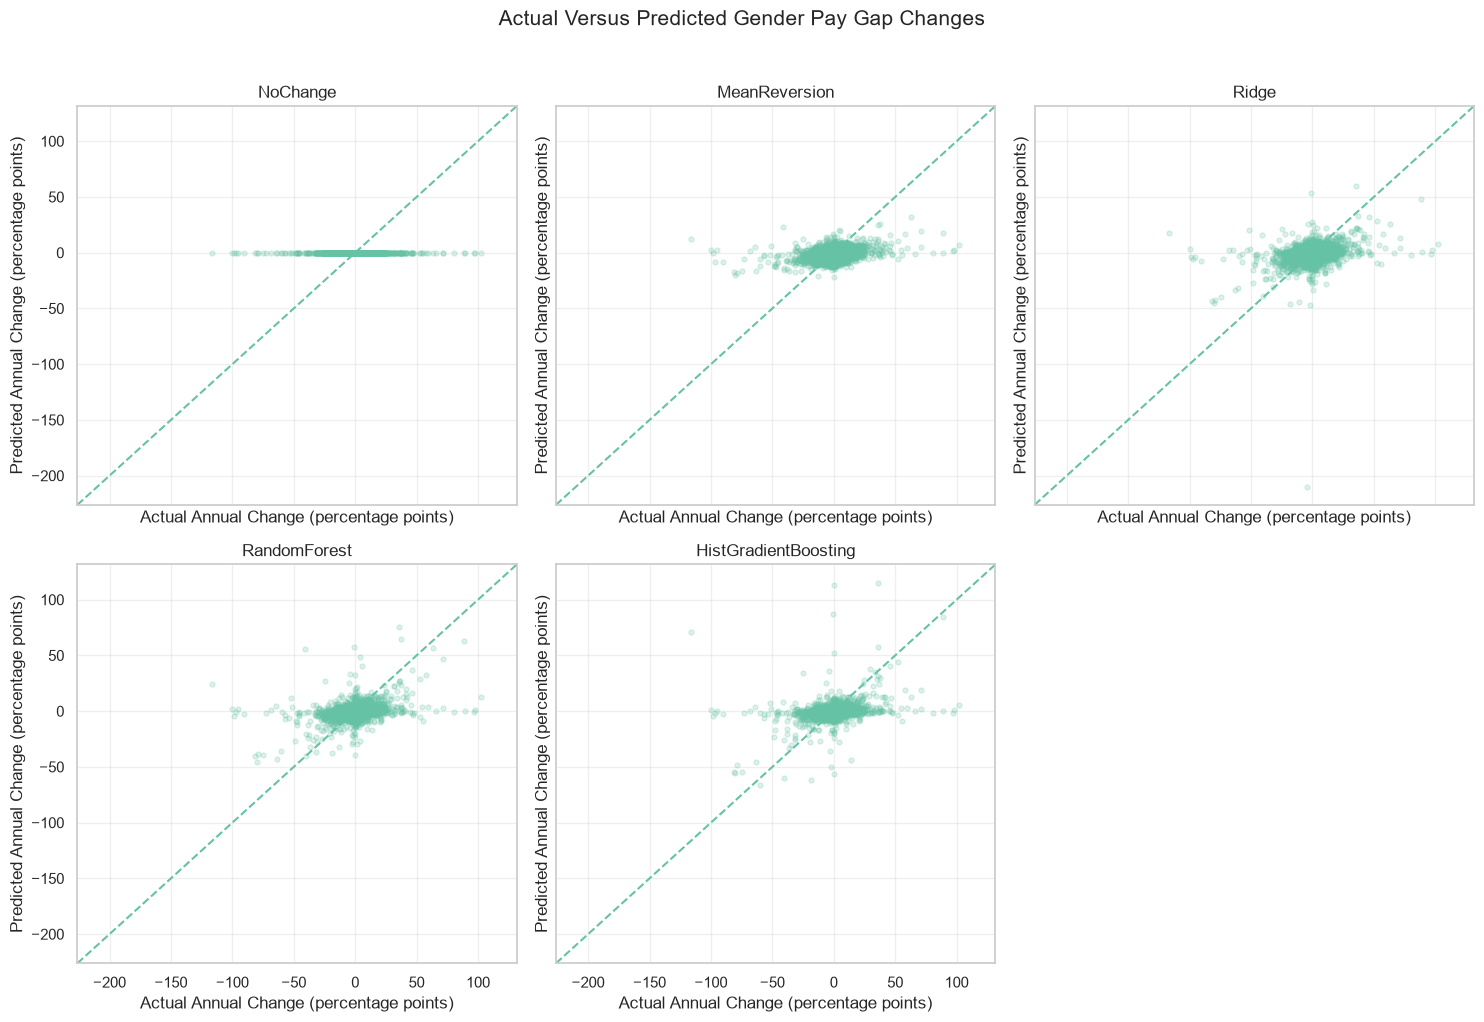

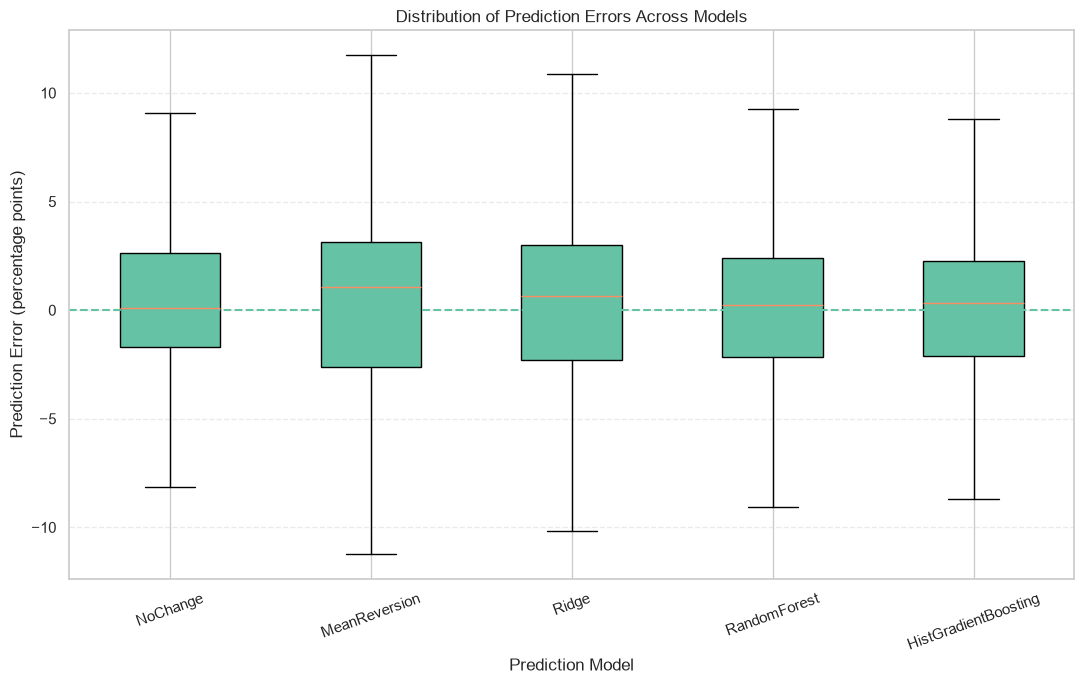

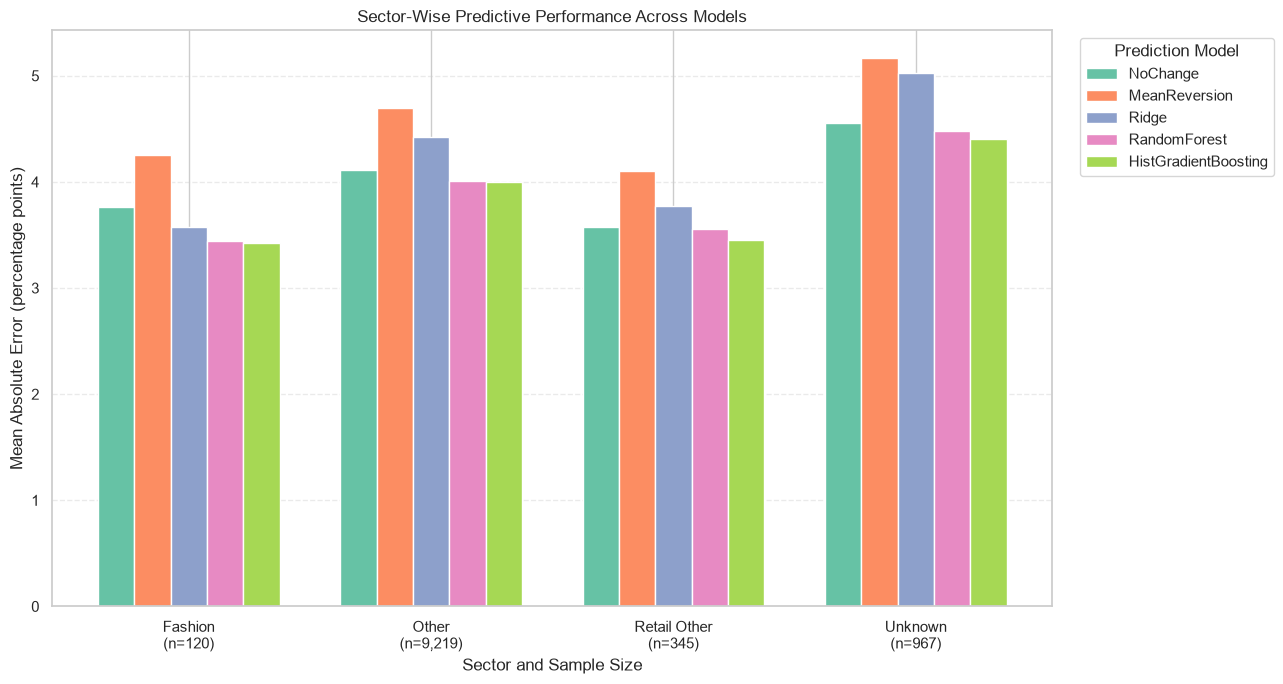


SECTOR-WISE MAE RESULTS


,sector,n,NoChange,MeanReversion,Ridge,RandomForest,HistGradientBoosting
0,fashion,120,3.7634,4.2516,3.5767,3.4391,3.4232
1,other,9219,4.1130,4.6918,4.4234,4.0097,3.9989
2,retail_other,345,3.5772,4.1039,3.7703,3.5569,3.4516
3,unknown,967,4.5507,5.1682,5.0253,4.4823,4.4044



ACTUAL VS PREDICTED VISUALISATIONS COMPLETED
figure_actual_vs_predicted.png: SAVED
figure_prediction_error_distribution.png: SAVED
figure_sector_wise_mae.png: SAVED

Figure directory: C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\research_figures


In [21]:

# ============================================================
# ACTUAL VS PREDICTED VISUALISATIONS
# UK GENDER PAY GAP PREDICTION PROJECT
# Uses existing final_predictions_2024.csv
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. LOAD EXISTING PREDICTIONS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project"
)

TABLE_DIR = PROJECT_DIR / "outputs" / "main" / "tables"
FIGURE_DIR = PROJECT_DIR / "outputs" / "research_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

predictions = pd.read_csv(
    TABLE_DIR / "final_predictions_2024.csv"
)

models = [
    "NoChange",
    "MeanReversion",
    "Ridge",
    "RandomForest",
    "HistGradientBoosting"
]

required_columns = ["y_true", "sector"] + models

missing = [
    col for col in required_columns
    if col not in predictions.columns
]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Ensure numeric values
for col in ["y_true"] + models:
    predictions[col] = pd.to_numeric(
        predictions[col],
        errors="coerce"
    )

print("Prediction dataset:", predictions.shape)
print("Observations:", len(predictions))
print("Models:", models)


# ============================================================
# FIGURE 1: ACTUAL VS PREDICTED CHANGES
# ============================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 10),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

valid_actual = predictions["y_true"].dropna()

all_values = [valid_actual]

for model in models:
    all_values.append(predictions[model].dropna())

global_min = min(values.min() for values in all_values)
global_max = max(values.max() for values in all_values)

margin = (global_max - global_min) * 0.05
plot_min = global_min - margin
plot_max = global_max + margin

for i, model in enumerate(models):

    plot_data = predictions[
        ["y_true", model]
    ].dropna()

    axes[i].scatter(
        plot_data["y_true"],
        plot_data[model],
        alpha=0.22,
        s=13
    )

    axes[i].plot(
        [plot_min, plot_max],
        [plot_min, plot_max],
        linestyle="--",
        linewidth=1.5
    )

    axes[i].set_title(model)
    axes[i].set_xlim(plot_min, plot_max)
    axes[i].set_ylim(plot_min, plot_max)
    axes[i].grid(alpha=0.3)

    axes[i].set_xlabel(
        "Actual Annual Change (percentage points)"
    )

    axes[i].set_ylabel(
        "Predicted Annual Change (percentage points)"
    )

# Remove unused sixth panel
fig.delaxes(axes[5])

fig.suptitle(
    "Actual Versus Predicted Gender Pay Gap Changes",
    fontsize=15,
    y=1.02
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "figure_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2: PREDICTION ERROR DISTRIBUTION
# Residual = Predicted - Actual
# ============================================================

residuals = []

for model in models:

    errors = (
        predictions[model] - predictions["y_true"]
    ).dropna()

    residuals.append(errors)

fig, ax = plt.subplots(figsize=(11, 7))

ax.boxplot(
    residuals,
    tick_labels=models,
    showfliers=False,
    patch_artist=True
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1.5
)

ax.set_title(
    "Distribution of Prediction Errors Across Models"
)

ax.set_xlabel("Prediction Model")
ax.set_ylabel(
    "Prediction Error (percentage points)"
)

ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", linestyle="--", alpha=0.4)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "figure_prediction_error_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 3: SECTOR-WISE MAE COMPARISON
# ============================================================

sector_results = []

for sector, sector_data in predictions.groupby(
    "sector",
    dropna=False
):

    row = {
        "sector": str(sector),
        "n": len(sector_data)
    }

    for model in models:
        valid = sector_data[
            ["y_true", model]
        ].dropna()

        row[model] = np.mean(
            np.abs(valid[model] - valid["y_true"])
        )

    sector_results.append(row)

sector_metrics = pd.DataFrame(sector_results)

sector_metrics = sector_metrics.sort_values(
    "sector"
)

fig, ax = plt.subplots(figsize=(13, 7))

x = np.arange(len(sector_metrics))
width = 0.15

for i, model in enumerate(models):

    offset = (i - 2) * width

    ax.bar(
        x + offset,
        sector_metrics[model],
        width,
        label=model
    )

sector_labels = [
    f"{row['sector'].replace('_', ' ').title()}\n(n={row['n']:,})"
    for _, row in sector_metrics.iterrows()
]

ax.set_xticks(x)
ax.set_xticklabels(sector_labels)

ax.set_xlabel("Sector and Sample Size")
ax.set_ylabel("Mean Absolute Error (percentage points)")

ax.set_title(
    "Sector-Wise Predictive Performance Across Models"
)

ax.legend(
    title="Prediction Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(axis="y", linestyle="--", alpha=0.4)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "figure_sector_wise_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 4. PRINT SECTOR PERFORMANCE TABLE
# ============================================================

print("\nSECTOR-WISE MAE RESULTS")
display(
    sector_metrics.round(4)
)


# ============================================================
# 5. COMPLETION
# ============================================================

print("\n" + "=" * 65)
print("ACTUAL VS PREDICTED VISUALISATIONS COMPLETED")
print("=" * 65)

for filename in [
    "figure_actual_vs_predicted.png",
    "figure_prediction_error_distribution.png",
    "figure_sector_wise_mae.png"
]:
    path = FIGURE_DIR / filename
    print(f"{filename}: {'SAVED' if path.exists() else 'NOT FOUND'}")

print("\nFigure directory:", FIGURE_DIR)


## verifying results

In [22]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    r"C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project"
)

OUTPUT_DIR = PROJECT_DIR / "outputs" / "main" / "tables"

files_to_inspect = [
    "classification_results_2024.csv",
    "classification_class_shares_2024.csv",
    "final_predictions_2024.csv"
]

for filename in files_to_inspect:

    path = OUTPUT_DIR / filename

    print("\n" + "=" * 65)
    print(filename)
    print("=" * 65)

    if path.exists():
        df = pd.read_csv(path)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(10))
    else:
        print("File not found:", path)


# Locate existing confusion matrices and classification outputs
print("\nOTHER CLASSIFICATION OUTPUT FILES")

for folder in [
    PROJECT_DIR / "outputs" / "main",
    PROJECT_DIR / "outputs"
]:
    if folder.exists():
        for path in folder.rglob("*"):
            if path.is_file() and any(
                word in path.name.lower()
                for word in ["confusion", "classification", "class_prediction"]
            ):
                print(path)



classification_results_2024.csv
Shape: (5, 6)
Columns: ['model', 'balanced_accuracy', 'macro_F1', 'recall_decrease', 'recall_stable', 'recall_increase']


,model,balanced_accuracy,macro_F1,recall_decrease,recall_stable,recall_increase
0,NoChange,0.333333,0.157841,0.000000,1.000000,0.000000
1,MeanReversion,0.365478,0.353670,0.446368,0.161622,0.488444
2,Ridge,0.418682,0.416637,0.457582,0.321731,0.476733
3,RandomForest,0.466344,0.461696,0.485617,0.575666,0.337750
4,HistGradientBoosting,0.456310,0.439088,0.426134,0.688559,0.254237



classification_class_shares_2024.csv
Shape: (3, 2)
Columns: ['class', 'proportion']


,class,proportion
0,decrease,0.385128
1,stable,0.310206
2,increase,0.304666



final_predictions_2024.csv
Shape: (10651, 9)
Columns: ['employer_id', 'report_year', 'sector', 'y_true', 'NoChange', 'MeanReversion', 'Ridge', 'RandomForest', 'HistGradientBoosting']


,employer_id,report_year,sector,y_true,NoChange,MeanReversion,Ridge,RandomForest,HistGradientBoosting
0,100,2024,other,0.49,0.0,-7.986669,-7.550560,-2.894334,-2.600373
1,10004,2024,other,0.10,0.0,2.150172,3.567179,1.368683,0.667017
2,10007,2024,other,-1.90,0.0,4.666238,2.169205,1.530824,1.728670
3,10008,2024,other,-0.02,0.0,-1.306999,-2.153388,-3.009684,-2.238549
4,10009,2024,other,0.00,0.0,-0.900557,0.261584,0.206976,0.807074
5,10010,2024,retail_other,-0.30,0.0,2.295330,-0.223624,0.431454,0.484538
6,10016,2024,unknown,0.30,0.0,1.327612,2.724862,1.129407,0.997963
7,10017,2024,other,0.00,0.0,-5.833498,-4.249144,-2.047969,-1.572900
8,10024,2024,fashion,1.00,0.0,2.440487,1.423486,1.308964,0.933798
9,10027,2024,other,-0.20,0.0,2.972732,0.925833,0.357149,0.415704



OTHER CLASSIFICATION OUTPUT FILES
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\main\tables\classification_class_shares_2024.csv
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\main\tables\classification_results_2024.csv
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\main\tables\confusion_matrix_HistGradientBoosting.csv
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\main\tables\confusion_matrix_MeanReversion.csv
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\main\tables\confusion_matrix_NoChange.csv
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\main\tables\confusion_matrix_RandomForest.csv
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outpu

## classification visualisations


RECONSTRUCTED CLASSIFICATION METRICS


,model,balanced_accuracy,macro_F1,recall_decrease,recall_stable,recall_increase
0,NoChange,0.3333,0.1578,0.0000,1.0000,0.0000
1,MeanReversion,0.3655,0.3537,0.4464,0.1616,0.4884
2,Ridge,0.4187,0.4166,0.4576,0.3217,0.4767
3,RandomForest,0.4663,0.4617,0.4856,0.5757,0.3378
4,HistGradientBoosting,0.4563,0.4391,0.4261,0.6886,0.2542



VALIDATION AGAINST SAVED RESULTS


,model,balanced_accuracy_difference,macro_F1_difference,recall_decrease_difference,recall_stable_difference,recall_increase_difference
0,NoChange,0.0,0.0,0.0,0.0,0.0
1,MeanReversion,0.0,0.0,0.0,0.0,0.0
2,Ridge,0.0,0.0,0.0,0.0,0.0
3,RandomForest,0.0,0.0,0.0,0.0,0.0
4,HistGradientBoosting,0.0,0.0,0.0,0.0,0.0



VALIDATION PASSED: Reconstructed metrics match the saved classification results.


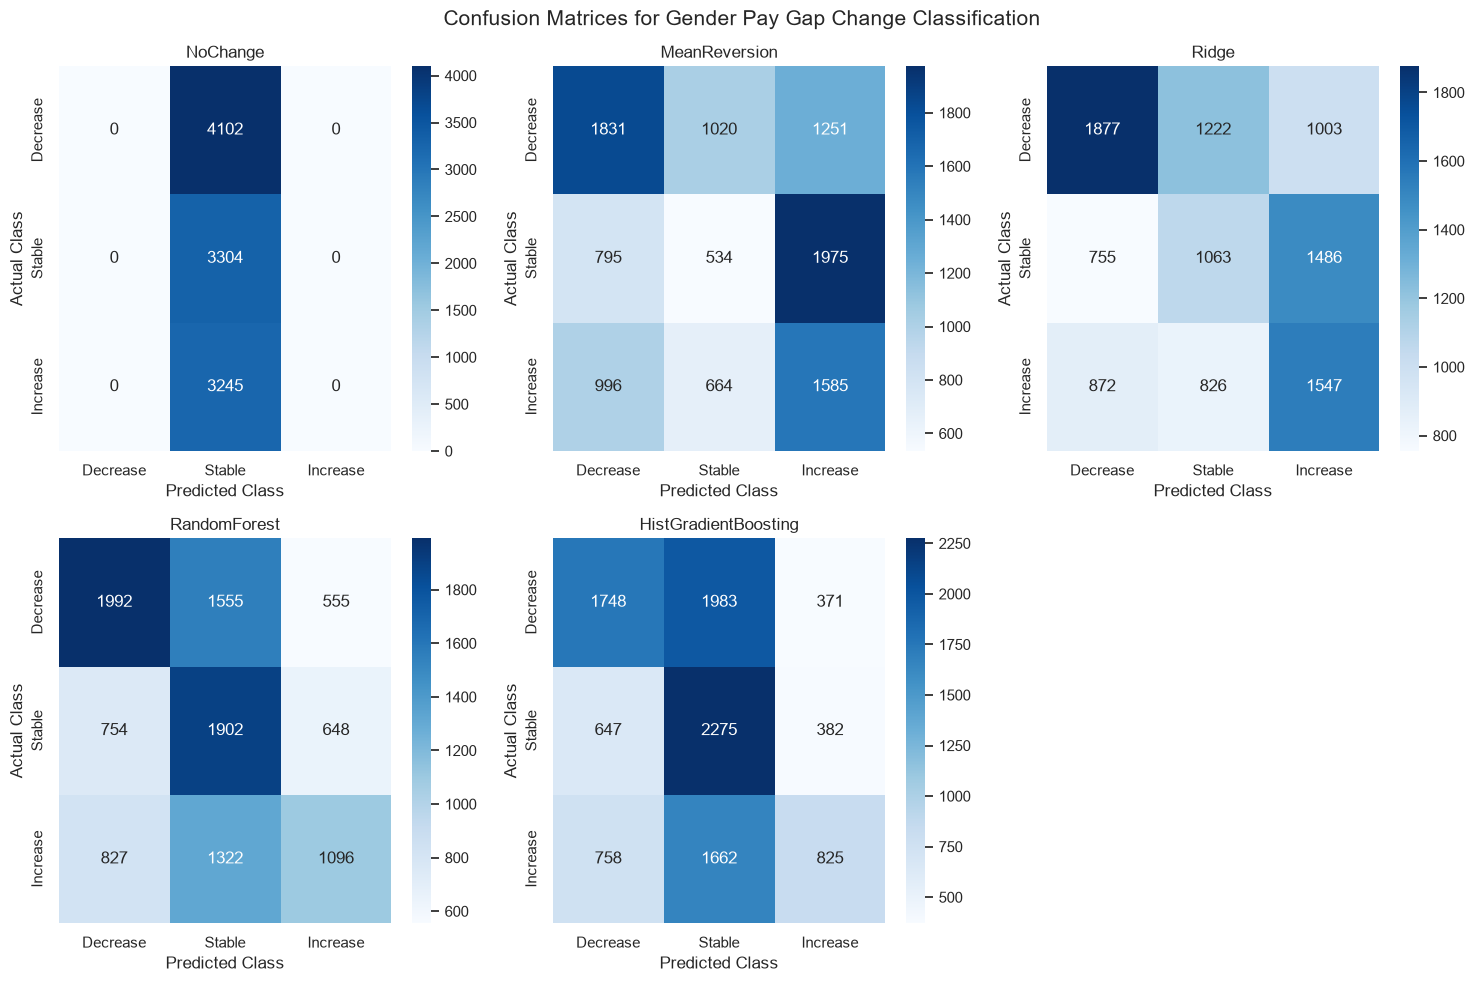

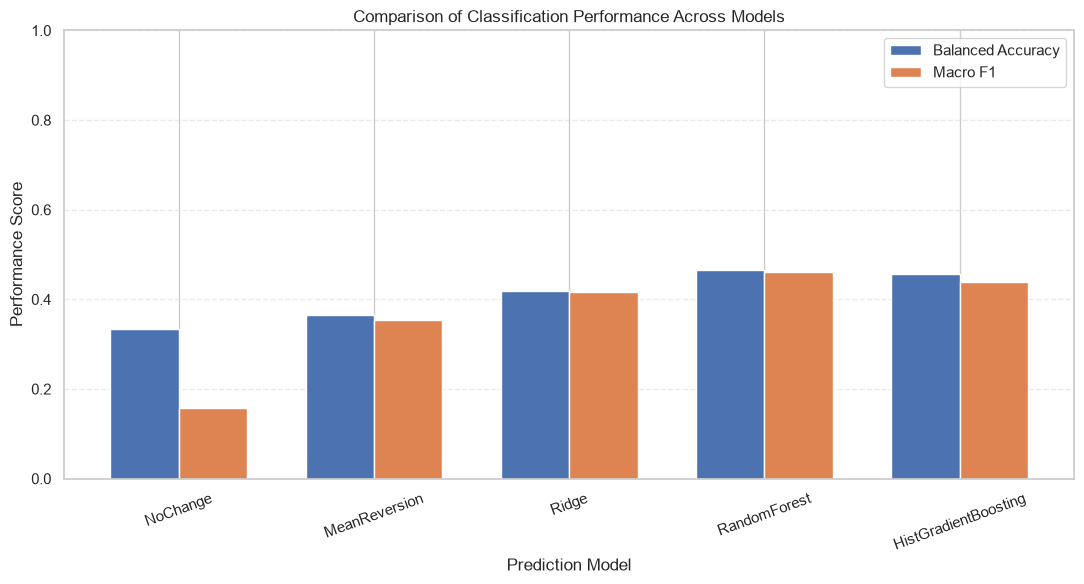

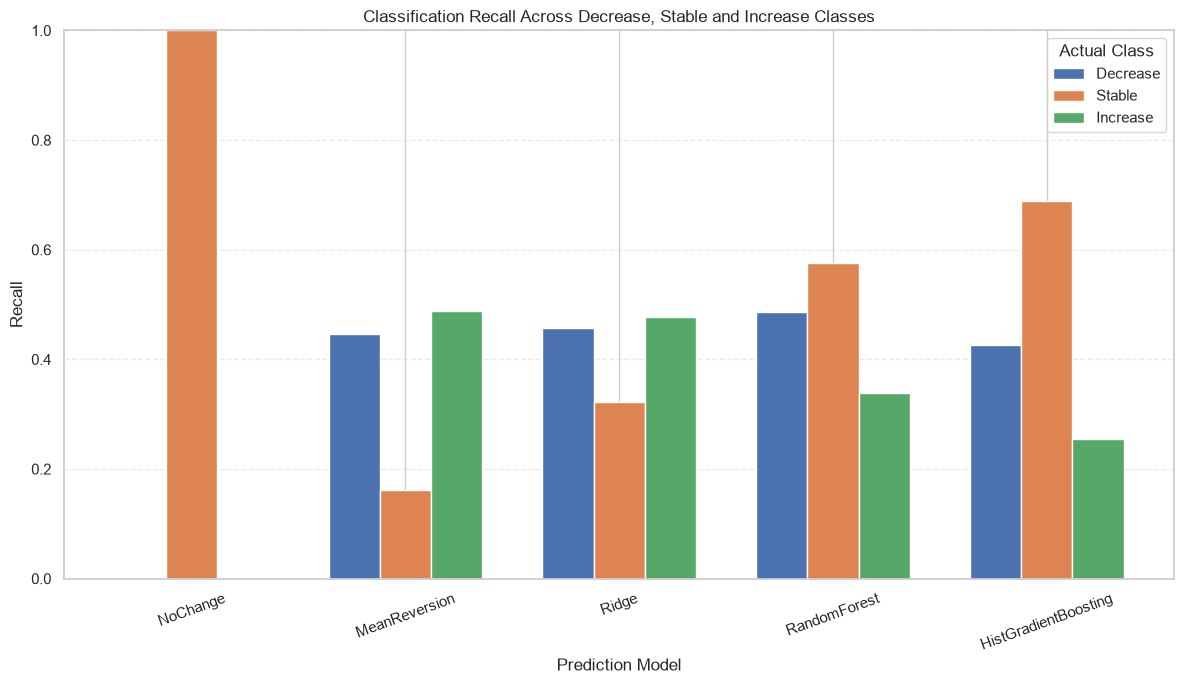


CLASSIFICATION VISUALISATIONS COMPLETED
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\research_figures\figure_classification_class_recall.png
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\research_figures\figure_classification_confusion_matrices.png
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\research_figures\figure_classification_model_comparison.png

Figure directory: C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\research_figures


In [23]:

# ============================================================
# CLASSIFICATION VISUALISATIONS
# UK GENDER PAY GAP PREDICTION PROJECT
# Uses existing saved predictions and classification results
# No model retraining
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score,
    recall_score
)

sns.set_theme(style="whitegrid")

# ------------------------------------------------------------
# 1. LOAD EXISTING RESULTS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project"
)

TABLE_DIR = PROJECT_DIR / "outputs" / "main" / "tables"
FIGURE_DIR = PROJECT_DIR / "outputs" / "research_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

predictions = pd.read_csv(
    TABLE_DIR / "final_predictions_2024.csv"
)

saved_metrics = pd.read_csv(
    TABLE_DIR / "classification_results_2024.csv"
)

models = [
    "NoChange",
    "MeanReversion",
    "Ridge",
    "RandomForest",
    "HistGradientBoosting"
]

class_labels = ["Decrease", "Stable", "Increase"]
class_codes = [0, 1, 2]

# ------------------------------------------------------------
# 2. CONVERT CONTINUOUS VALUES INTO THREE CLASSES
# ------------------------------------------------------------

def classify_change(values):
    """
    Decrease: change < -1
    Stable:   -1 <= change <= 1
    Increase: change > 1
    """

    values = np.asarray(values, dtype=float)

    result = np.full(len(values), -1, dtype=int)
    valid = np.isfinite(values)

    result[valid & (values < -1)] = 0
    result[valid & (values >= -1) & (values <= 1)] = 1
    result[valid & (values > 1)] = 2

    return result


y_true = classify_change(predictions["y_true"])

y_predictions = {
    model: classify_change(predictions[model])
    for model in models
}

valid_actual = y_true != -1

# ------------------------------------------------------------
# 3. RECONSTRUCT CLASSIFICATION METRICS
# ------------------------------------------------------------

reconstructed_results = []

for model in models:

    y_pred = y_predictions[model]

    valid = valid_actual & (y_pred != -1)

    actual = y_true[valid]
    predicted = y_pred[valid]

    reconstructed_results.append({
        "model": model,
        "balanced_accuracy": balanced_accuracy_score(
            actual, predicted
        ),
        "macro_F1": f1_score(
            actual, predicted,
            labels=class_codes,
            average="macro",
            zero_division=0
        ),
        "recall_decrease": recall_score(
            actual, predicted,
            labels=class_codes,
            average=None,
            zero_division=0
        )[0],
        "recall_stable": recall_score(
            actual, predicted,
            labels=class_codes,
            average=None,
            zero_division=0
        )[1],
        "recall_increase": recall_score(
            actual, predicted,
            labels=class_codes,
            average=None,
            zero_division=0
        )[2]
    })

reconstructed = pd.DataFrame(reconstructed_results)

print("\nRECONSTRUCTED CLASSIFICATION METRICS")
display(reconstructed.round(4))

# ------------------------------------------------------------
# 4. VALIDATE AGAINST SAVED CLASSIFICATION RESULTS
# ------------------------------------------------------------

comparison = reconstructed.merge(
    saved_metrics,
    on="model",
    suffixes=("_reconstructed", "_saved")
)

metric_columns = [
    "balanced_accuracy",
    "macro_F1",
    "recall_decrease",
    "recall_stable",
    "recall_increase"
]

print("\nVALIDATION AGAINST SAVED RESULTS")

for metric in metric_columns:
    comparison[f"{metric}_difference"] = (
        comparison[f"{metric}_reconstructed"]
        - comparison[f"{metric}_saved"]
    )

display(
    comparison[
        ["model"] +
        [f"{m}_difference" for m in metric_columns]
    ].round(6)
)

matches = all(
    np.allclose(
        comparison[f"{metric}_reconstructed"],
        comparison[f"{metric}_saved"],
        atol=0.001
    )
    for metric in metric_columns
)

if matches:
    print(
        "\nVALIDATION PASSED: Reconstructed metrics match "
        "the saved classification results."
    )
else:
    print(
        "\nVALIDATION WARNING: Reconstructed metrics do not "
        "fully match saved results. Check the classification "
        "threshold convention before using these confusion matrices."
    )

# ============================================================
# FIGURE 1: CONFUSION MATRICES FOR ALL FIVE MODELS
# ============================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 10)
)

axes = axes.flatten()

for i, model in enumerate(models):

    y_pred = y_predictions[model]

    valid = valid_actual & (y_pred != -1)

    cm = confusion_matrix(
        y_true[valid],
        y_pred[valid],
        labels=class_codes
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=axes[i]
    )

    axes[i].set_title(model)
    axes[i].set_xlabel("Predicted Class")
    axes[i].set_ylabel("Actual Class")

fig.delaxes(axes[5])

fig.suptitle(
    "Confusion Matrices for Gender Pay Gap Change Classification",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "figure_classification_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2: BALANCED ACCURACY AND MACRO F1
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(reconstructed))
width = 0.35

ax.bar(
    x - width / 2,
    reconstructed["balanced_accuracy"],
    width,
    label="Balanced Accuracy"
)

ax.bar(
    x + width / 2,
    reconstructed["macro_F1"],
    width,
    label="Macro F1"
)

ax.set_xticks(x)
ax.set_xticklabels(reconstructed["model"], rotation=20)

ax.set_ylim(0, 1)

ax.set_ylabel("Performance Score")
ax.set_xlabel("Prediction Model")

ax.set_title(
    "Comparison of Classification Performance Across Models"
)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "figure_classification_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 3: RECALL BY CLASS
# ============================================================

recall_columns = [
    "recall_decrease",
    "recall_stable",
    "recall_increase"
]

recall_labels = [
    "Decrease",
    "Stable",
    "Increase"
]

fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(reconstructed))
width = 0.24

for i, (column, label) in enumerate(
    zip(recall_columns, recall_labels)
):

    ax.bar(
        x + (i - 1) * width,
        reconstructed[column],
        width,
        label=label
    )

ax.set_xticks(x)
ax.set_xticklabels(reconstructed["model"], rotation=20)

ax.set_ylim(0, 1)

ax.set_ylabel("Recall")
ax.set_xlabel("Prediction Model")

ax.set_title(
    "Classification Recall Across Decrease, Stable and Increase Classes"
)

ax.legend(title="Actual Class")
ax.grid(axis="y", linestyle="--", alpha=0.4)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "figure_classification_class_recall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# COMPLETION
# ============================================================

print("\n" + "=" * 65)
print("CLASSIFICATION VISUALISATIONS COMPLETED")
print("=" * 65)

for file in sorted(
    FIGURE_DIR.glob("figure_classification_*.png")
):
    print(file)

print("\nFigure directory:", FIGURE_DIR)


In [24]:
import pandas as pd
from pathlib import Path

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

file_path = project_dir / "outputs" / "main" / "tables" / "ablation_results_2023.csv"

if not file_path.exists():
    file_path = project_dir / "outputs" / "ablation_results_2023.csv"

ablation = pd.read_csv(file_path)

print("ABLATION RESULTS")
print("Shape:", ablation.shape)
print("\nColumns:")
print(ablation.columns.tolist())
print("\nFull results:")
display(ablation)

ABLATION RESULTS
Shape: (10585, 8)

Columns:
['employer_id', 'report_year', 'sector', 'y_true', 'BASE', 'BASE+BONUS', 'BASE+QUARTILE', 'FULL']

Full results:


,employer_id,report_year,sector,y_true,BASE,BASE+BONUS,BASE+QUARTILE,FULL
0,100,2023,other,2.90,-2.750667,-2.672970,-2.494503,-2.419771
1,10004,2023,other,-0.50,-0.502118,-0.479998,-0.301259,-0.349006
2,10007,2023,other,0.70,2.503726,2.558048,1.895598,2.122056
3,10008,2023,other,5.17,-0.184190,0.083362,0.048489,-0.117304
4,10009,2023,other,-11.18,-6.283237,-6.788602,-6.910050,-6.773431
...,...,...,...,...,...,...,...,...
10580,9991,2023,other,0.00,-0.724477,-0.696961,-0.746024,-0.695825
10581,9993,2023,other,-0.80,-2.881546,-3.222240,-2.751255,-2.782538
10582,9995,2023,other,0.03,0.511346,0.477446,0.591037,0.613294
10583,9998,2023,other,-9.50,-1.206360,-1.156769,-1.422525,-1.393377


## Ablation results

In [25]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

file_path = project_dir / "outputs" / "main" / "tables" / "ablation_results_2023.csv"

if not file_path.exists():
    file_path = project_dir / "outputs" / "ablation_results_2023.csv"

df = pd.read_csv(file_path)

prediction_columns = [
    "BASE",
    "BASE+BONUS",
    "BASE+QUARTILE",
    "FULL"
]

results = []

for model in prediction_columns:
    valid = df[["y_true", model]].dropna()

    results.append({
        "Configuration": model,
        "N": len(valid),
        "MAE": mean_absolute_error(valid["y_true"], valid[model]),
        "RMSE": np.sqrt(mean_squared_error(valid["y_true"], valid[model])),
        "R2": r2_score(valid["y_true"], valid[model])
    })

ablation_metrics = pd.DataFrame(results)

print("ABLATION PERFORMANCE COMPARISON")
display(ablation_metrics.round(4))

print("\nBest configuration by MAE:")
print(ablation_metrics.loc[ablation_metrics["MAE"].idxmin()].to_string())

print("\nBest configuration by RMSE:")
print(ablation_metrics.loc[ablation_metrics["RMSE"].idxmin()].to_string())

ABLATION PERFORMANCE COMPARISON


,Configuration,N,MAE,RMSE,R2
0,BASE,10585,4.1565,9.5722,0.1804
1,BASE+BONUS,10585,4.1551,9.6020,0.1753
2,BASE+QUARTILE,10585,4.1245,9.5277,0.1880
3,FULL,10585,4.1260,9.5375,0.1864



Best configuration by MAE:
Configuration    BASE+QUARTILE
N                        10585
MAE                   4.124489
RMSE                  9.527651
R2                    0.188039

Best configuration by RMSE:
Configuration    BASE+QUARTILE
N                        10585
MAE                   4.124489
RMSE                  9.527651
R2                    0.188039


## final ablation study

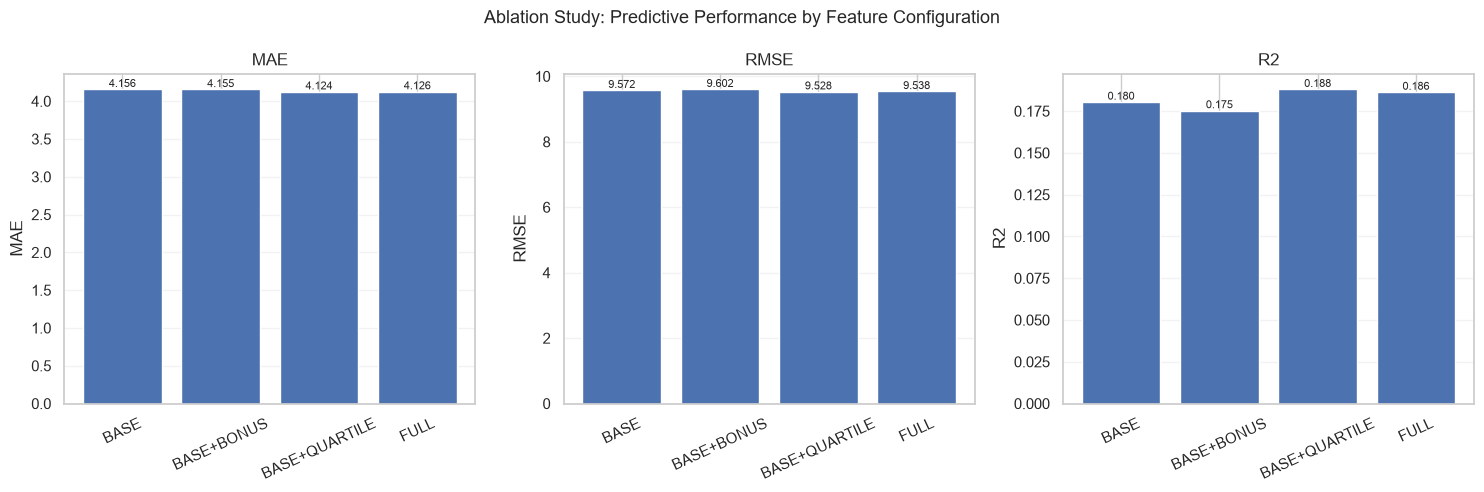

Saved: c:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\research_figures\figure_ablation_comparison.png


In [26]:

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

output_dir = project_dir / "outputs" / "research_figures"
output_dir.mkdir(parents=True, exist_ok=True)

metrics = ["MAE", "RMSE", "R2"]
configurations = ablation_metrics["Configuration"].tolist()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metric in zip(axes, metrics):
    values = ablation_metrics[metric].values

    bars = ax.bar(configurations, values)

    ax.set_title(metric)
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height(),
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=8
        )

fig.suptitle(
    "Ablation Study: Predictive Performance by Feature Configuration",
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    output_dir / "figure_ablation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_dir / "figure_ablation_comparison.png")
